# Cuaderno de acompañamiento del capítulo 8
## Probabilidad y estadística para estudiantes de filosofía

Este cuaderno acompaña al capítulo 8 del libro (*Probabilidad e inferencia: el azar, la estadística y el peso de la evidencia*). No repite su argumento filosófico: lo que hace es permitirte **ver funcionar** las nociones que el capítulo discute —probabilidad, tasa de base, actualización bayesiana, muestreo, contraste de hipótesis, comparaciones múltiples— con números que podés cambiar. Cada sección indica a qué parágrafo (§) del capítulo corresponde.

**No hace falta saber programar.** Cada celda de código está comentada; para ejecutarla, seleccionala y apretá `Shift+Enter`. Lo único que conviene hacer es cambiar los números marcados con `# <- probá cambiar esto` y volver a ejecutar, para comprobar que entendiste qué depende de qué.

**Qué necesitás.** Python 3 con `numpy`, `matplotlib` y `scipy` (ver `requirements.txt` en el repositorio). Si abrís el cuaderno en un servicio en línea (por ejemplo, Binder o Colab), esas bibliotecas suelen estar preinstaladas.

**Una advertencia de método.** Vamos a usar *simulaciones*: la computadora tira dados, saca cartas y sortea muestras miles de veces. Eso es exactamente lo que el capítulo 7 (§6) llama "el laboratorio de la representación": experimentamos con modelos, no con el mundo. Cuando una simulación muestra que "el 95 % de los intervalos contienen el valor verdadero", está mostrando una propiedad del procedimiento que programamos, no un hecho sobre ningún experimento real. Tener eso presente es parte del aprendizaje.

In [1]:
# Preparación: importamos las bibliotecas y fijamos una "semilla" para que los sorteos
# aleatorios sean reproducibles (si cambiás la semilla, cambian los números, no las conclusiones).
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)   # <- probá cambiar esto
plt.rcParams["figure.figsize"] = (7, 3.6)
plt.rcParams["axes.grid"] = True
print("Listo: numpy", np.__version__)

Listo: numpy 2.5.3


## 1. Contar posibilidades y tirar dados (§2 y §3)

El capítulo distingue tres cosas que uno puede querer decir con "la probabilidad de sacar un seis es 1/6": una relación entre casos favorables y casos posibles (interpretación clásica), una frecuencia relativa a largo plazo (frecuentista) o un grado de creencia (personalista). La simulación muestra cómo se relacionan las dos primeras: la *frecuencia relativa* de seises se acerca a 1/6 a medida que crece el número de tiradas, aunque nunca lo iguala exactamente y aunque al principio se aleje bastante.

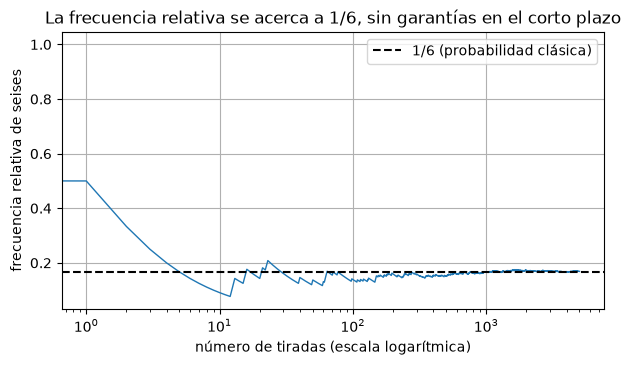

Después de 5000 tiradas: 0.1688 (1/6 = 0.1667)


In [2]:
n_tiradas = 5000                      # <- probá cambiar esto
tiradas = rng.integers(1, 7, size=n_tiradas)          # dados de seis caras
frecuencia_acumulada = np.cumsum(tiradas == 6) / np.arange(1, n_tiradas + 1)

plt.plot(frecuencia_acumulada, lw=1)
plt.axhline(1/6, color="k", ls="--", label="1/6 (probabilidad clásica)")
plt.xscale("log")
plt.xlabel("número de tiradas (escala logarítmica)")
plt.ylabel("frecuencia relativa de seises")
plt.legend(); plt.title("La frecuencia relativa se acerca a 1/6, sin garantías en el corto plazo")
plt.show()
print(f"Después de {n_tiradas} tiradas: {frecuencia_acumulada[-1]:.4f} (1/6 = {1/6:.4f})")

### Dos cálculos que engañan a la intuición

El capítulo recuerda (con Salmon) que la probabilidad de obtener *al menos* un seis en tres tiradas no es 3/6, como sugiere la suma apresurada, sino $1 - (5/6)^3 = 91/216 \approx 0{,}42$. Y que la pregunta del caballero De Méré —¿sale al menos un doble seis en 24 tiradas de dos dados?— tiene por respuesta una probabilidad *algo menor* que un medio: $1 - (35/36)^{24} \approx 0{,}491$. Comprobemos ambas cosas de las dos maneras: calculando y simulando.

In [3]:
# Cálculo exacto
p_tres_tiradas = 1 - (5/6)**3
p_de_mere = 1 - (35/36)**24
print(f"Al menos un seis en 3 tiradas:        {p_tres_tiradas:.4f}  (= 91/216 = {91/216:.4f})")
print(f"Al menos un doble seis en 24 tiradas: {p_de_mere:.4f}")

# Simulación: repetimos el juego muchas veces y contamos en qué fracción se gana
repeticiones = 100_000
juego1 = rng.integers(1, 7, size=(repeticiones, 3))
gana1 = (juego1 == 6).any(axis=1).mean()
juego2 = rng.integers(1, 7, size=(repeticiones, 24, 2))
gana2 = ((juego2 == 6).all(axis=2)).any(axis=1).mean()
print(f"\nSimulación ({repeticiones} partidas): {gana1:.4f} y {gana2:.4f}")
print("De Méré perdía dinero apostando a favor del doble seis porque 0,491 < 0,5: la diferencia es pequeña,")
print("pero a largo plazo la casa la cobra.")

Al menos un seis en 3 tiradas:        0.4213  (= 91/216 = 0.4213)
Al menos un doble seis en 24 tiradas: 0.4914

Simulación (100000 partidas): 0.4191 y 0.4914
De Méré perdía dinero apostando a favor del doble seis porque 0,491 < 0,5: la diferencia es pequeña,
pero a largo plazo la casa la cobra.


## 2. Probabilidad condicional y el teorema de Bayes (§3)

El teorema de Bayes dice cómo debe cambiar la probabilidad de una hipótesis $H$ cuando se observa una evidencia $E$:

$$\Pr(H \mid E) = \frac{\Pr(E \mid H)\,\Pr(H)}{\Pr(E \mid H)\,\Pr(H) + \Pr(E \mid \neg H)\,\Pr(\neg H)}$$

El ejemplo del capítulo es un **cribado médico**: una afección que padece una persona de cada mil y una prueba que acierta el 90 % de las veces, tanto en enfermos como en sanos. Alguien da positivo. ¿Cuán probable es que esté enfermo? La respuesta —menos del 1 %— sorprende a casi todo el mundo, incluidos muchos profesionales. Es la *falacia de la tasa de base*: fijarse en la exactitud de la prueba y olvidar la prevalencia.

In [4]:
prevalencia = 1/1000     # Pr(H): tasa de base                      # <- probá cambiar esto
sensibilidad = 0.90      # Pr(positivo | enfermo)                    # <- probá cambiar esto
especificidad = 0.90     # Pr(negativo | sano)                       # <- probá cambiar esto

def posterior_positivo(prev, sens, esp):
    p_pos_enfermo = sens
    p_pos_sano = 1 - esp
    p_pos = p_pos_enfermo * prev + p_pos_sano * (1 - prev)   # probabilidad total del positivo
    return p_pos_enfermo * prev / p_pos, p_pos

post, p_pos = posterior_positivo(prevalencia, sensibilidad, especificidad)
print(f"Probabilidad total de dar positivo: {p_pos:.4f}")
print(f"Probabilidad de estar enfermo dado un positivo: {post:.4f}  (≈ {post*100:.2f} %)")

# La misma cuenta "en personas", que es como el capítulo la vuelve evidente
N = 10_000
enfermos = N * prevalencia
sanos = N - enfermos
pos_enf = enfermos * sensibilidad
pos_sanos = sanos * (1 - especificidad)
print(f"\nDe {N} examinados: {enfermos:.0f} enfermos, de los que dan positivo {pos_enf:.0f};")
print(f"{sanos:.0f} sanos, de los que dan positivo {pos_sanos:.0f}. De {pos_enf+pos_sanos:.0f} positivos, "
      f"solo {pos_enf:.0f} están enfermos.")

Probabilidad total de dar positivo: 0.1008
Probabilidad de estar enfermo dado un positivo: 0.0089  (≈ 0.89 %)

De 10000 examinados: 10 enfermos, de los que dan positivo 9;
9990 sanos, de los que dan positivo 999. De 1008 positivos, solo 9 están enfermos.


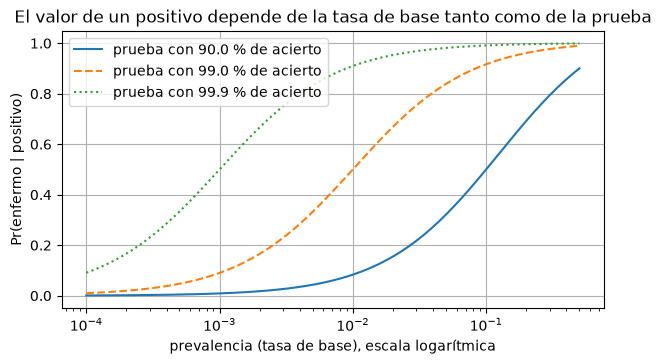

In [5]:
# ¿Qué pasa con la probabilidad posterior a medida que cambia la prevalencia?
prevs = np.logspace(-4, -0.3, 200)
for sens, esp, estilo in [(0.90, 0.90, "-"), (0.99, 0.99, "--"), (0.999, 0.999, ":")]:
    posts = [posterior_positivo(p, sens, esp)[0] for p in prevs]
    plt.plot(prevs, posts, estilo, label=f"prueba con {sens*100:.1f} % de acierto")
plt.xscale("log")
plt.xlabel("prevalencia (tasa de base), escala logarítmica")
plt.ylabel("Pr(enfermo | positivo)")
plt.title("El valor de un positivo depende de la tasa de base tanto como de la prueba")
plt.legend(); plt.show()

### Los dos mazos de Salmon

Hay dos mazos de doce cartas: uno con dos rojas y diez negras, otro con seis y seis. Se tira un dado: si sale 1, se saca una carta del mazo parejo; si no, del mazo predominantemente negro. Se gana con una carta roja. Si se ganó, ¿de qué mazo es más probable que haya salido la carta? La intuición dice "del parejo, que tiene tres veces más rojas"; el teorema de Bayes dice otra cosa, porque el mazo parejo se usa solo una de cada seis veces.

In [6]:
p_parejo = 1/6; p_negro = 5/6
p_roja_parejo = 6/12; p_roja_negro = 2/12
p_roja = p_parejo * p_roja_parejo + p_negro * p_roja_negro
p_parejo_dado_roja = p_parejo * p_roja_parejo / p_roja
print(f"Probabilidad de ganar: {p_roja:.4f} (= 2/9 = {2/9:.4f})")
print(f"Pr(mazo parejo | roja) = {p_parejo_dado_roja:.4f} (= 3/8): más probable que haya salido del mazo negro.")

# Simulación
partidas = 200_000
dado = rng.integers(1, 7, size=partidas)
mazo_parejo = dado == 1
roja = np.where(mazo_parejo, rng.random(partidas) < 0.5, rng.random(partidas) < 1/6)
print(f"Simulación: gana {roja.mean():.4f}; entre las rojas, vienen del mazo parejo {mazo_parejo[roja].mean():.4f}")

Probabilidad de ganar: 0.2222 (= 2/9 = 0.2222)
Pr(mazo parejo | roja) = 0.3750 (= 3/8): más probable que haya salido del mazo negro.
Simulación: gana 0.2230; entre las rojas, vienen del mazo parejo 0.3769


## 3. Actualizar creencias: el "lavado" de las probabilidades previas (§6)

Una objeción clásica al bayesianismo es que las probabilidades previas son subjetivas. Salmon responde con un resultado matemático: salvo que las previas sean 0 o 1, su peso disminuye a medida que se acumula evidencia, y personas que partieron de opiniones muy distintas convergen. Basta, dice, con que tengan la mente *entreabierta*.

Simulemos tres personas que quieren saber si una moneda está cargada. La moneda cae cara con probabilidad verdadera $\theta$ (que ellas no conocen). Cada una parte de una previa distinta sobre $\theta$ —una optimista, una escéptica, una indiferente— y las tres ven las mismas tiradas. Representamos las previas con distribuciones Beta, que se actualizan de manera muy simple: cada cara suma 1 al primer parámetro y cada cruz suma 1 al segundo.

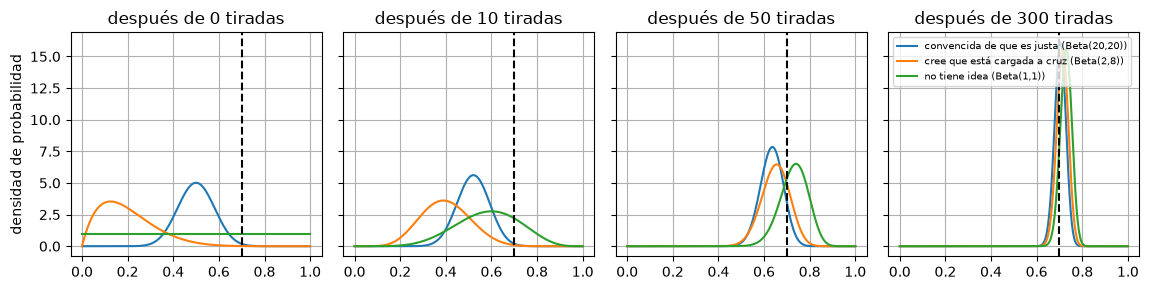

Con evidencia suficiente, las tres distribuciones se concentran alrededor del valor verdadero:
las previas 'se lavan'. Fijate cuántas tiradas tarda cada una: la previa fuerte (20,20) resiste más.


In [7]:
theta_verdadero = 0.7                                  # <- probá cambiar esto
n = 300
tiradas = rng.random(n) < theta_verdadero
previas = {"convencida de que es justa (Beta(20,20))": (20, 20),
           "cree que está cargada a cruz (Beta(2,8))": (2, 8),
           "no tiene idea (Beta(1,1))": (1, 1)}

x = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
for ax, k in zip(axes, [0, 10, 50, 300]):
    caras = tiradas[:k].sum(); cruces = k - caras
    for nombre, (a, b) in previas.items():
        ax.plot(x, stats.beta.pdf(x, a + caras, b + cruces), label=nombre)
    ax.axvline(theta_verdadero, color="k", ls="--")
    ax.set_title(f"después de {k} tiradas")
axes[0].set_ylabel("densidad de probabilidad")
axes[-1].legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()
print("Con evidencia suficiente, las tres distribuciones se concentran alrededor del valor verdadero:")
print("las previas 'se lavan'. Fijate cuántas tiradas tarda cada una: la previa fuerte (20,20) resiste más.")

Probá ahora una previa *dogmática*: `Beta(1000, 1000)` es alguien casi seguro de que la moneda es justa. Vas a ver que 300 tiradas no alcanzan para moverla. Eso es lo que el capítulo llama tener la mente cerrada: no una previa distinta, sino una previa que la evidencia no puede corregir en un tiempo razonable. (Y una previa de exactamente 0 o 1 no se mueve nunca: es el caso que Salmon excluye.)

## 4. Muestras, poblaciones e intervalos de confianza (§7)

La *estimación* infiere rasgos de una población a partir de una muestra. Dos lecciones del capítulo se dejan ver con simulaciones:

1. La precisión de una media muestral mejora con la **raíz cuadrada** del tamaño de la muestra: para reducir el error a la mitad hay que cuadruplicar la muestra.
2. Un intervalo de confianza del 95 % se construye con un procedimiento que, aplicado a las muestras posibles, contendría el valor verdadero en el 95 % de los casos. El 95 % califica al *procedimiento*, no a este intervalo particular, que contiene o no contiene el valor verdadero.

In [8]:
# Una "población": alturas (cm) con media 170 y desvío 8. En la vida real no conocemos estos valores;
# aquí los fijamos nosotros para poder comparar las estimaciones con la verdad.
media_pob, desvio_pob = 170, 8

for n in [10, 40, 160, 640]:
    medias = rng.normal(media_pob, desvio_pob, size=(5000, n)).mean(axis=1)
    print(f"n = {n:4d}: el desvío de las medias muestrales es {medias.std():.3f} "
          f"(teoría: {desvio_pob/np.sqrt(n):.3f})")

n =   10: el desvío de las medias muestrales es 2.534 (teoría: 2.530)
n =   40: el desvío de las medias muestrales es 1.261 (teoría: 1.265)
n =  160: el desvío de las medias muestrales es 0.620 (teoría: 0.632)
n =  640: el desvío de las medias muestrales es 0.310 (teoría: 0.316)


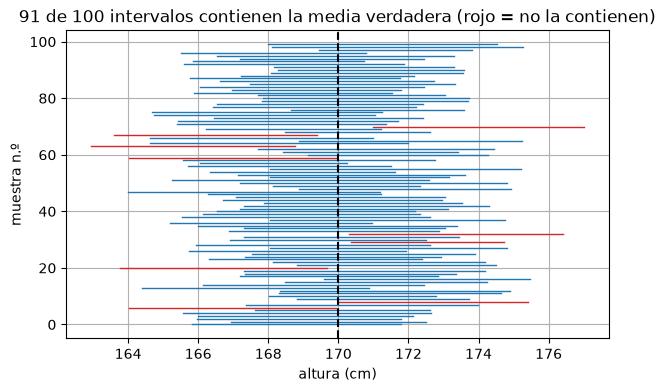

Cobertura en 20.000 muestras: 0.949


In [9]:
# Cobertura de los intervalos de confianza del 95 %
n = 30                                                  # <- probá cambiar esto
n_muestras = 100
fig, ax = plt.subplots(figsize=(7, 4))
dentro = 0
for i in range(n_muestras):
    muestra = rng.normal(media_pob, desvio_pob, size=n)
    m, s = muestra.mean(), muestra.std(ddof=1)
    semi = stats.t.ppf(0.975, df=n-1) * s / np.sqrt(n)
    contiene = (m - semi) <= media_pob <= (m + semi)
    dentro += contiene
    ax.plot([m - semi, m + semi], [i, i], color="tab:blue" if contiene else "tab:red", lw=1)
ax.axvline(media_pob, color="k", ls="--")
ax.set_xlabel("altura (cm)"); ax.set_ylabel("muestra n.º")
ax.set_title(f"{dentro} de {n_muestras} intervalos contienen la media verdadera (rojo = no la contienen)")
plt.show()

# A gran escala: ¿qué fracción de intervalos contiene el valor verdadero?
muestras = rng.normal(media_pob, desvio_pob, size=(20000, n))
m = muestras.mean(axis=1); s = muestras.std(axis=1, ddof=1)
semi = stats.t.ppf(0.975, df=n-1) * s / np.sqrt(n)
print(f"Cobertura en 20.000 muestras: {((m-semi <= media_pob) & (media_pob <= m+semi)).mean():.3f}")

### Cuando el tamaño no cura: el *Literary Digest* de 1936

Diez millones de tarjetas y 2,3 millones de respuestas no salvaron al *Literary Digest* de anunciar la victoria de Landon sobre Roosevelt: la lista de direcciones (guías telefónicas, registros de automóviles) sobrerrepresentaba a quienes tenían teléfono y auto en plena Depresión. Una muestra pequeña pero representativa, como la de Gallup, acertó. Simulemos una población con dos grupos que votan distinto y una encuesta cuya probabilidad de responder depende del grupo.

In [10]:
# Población: 1 millón de votantes; el 30 % "acomodados" vota 60 % por Landon; el 70 % restante, 35 %.
N = 1_000_000
acomodado = rng.random(N) < 0.30
vota_landon = np.where(acomodado, rng.random(N) < 0.60, rng.random(N) < 0.35)
print(f"Verdad en la población: Landon {vota_landon.mean()*100:.1f} %")

# Encuesta gigante pero sesgada: los acomodados responden 5 veces más
p_responde = np.where(acomodado, 0.50, 0.10)                     # <- probá cambiar esto
responde = rng.random(N) < p_responde
print(f"Encuesta sesgada ({responde.sum()} respuestas): Landon {vota_landon[responde].mean()*100:.1f} %")

# Encuesta chica pero aleatoria
muestra = rng.choice(N, size=1500, replace=False)
print(f"Muestra aleatoria (1500 personas): Landon {vota_landon[muestra].mean()*100:.1f} %")

Verdad en la población: Landon 42.5 %
Encuesta sesgada (219795 respuestas): Landon 52.1 %
Muestra aleatoria (1500 personas): Landon 41.7 %


## 5. Regresión a la media (§7)

Galton observó que las semillas hijas de madres extremas tendían a ser menos extremas que ellas. No es una fuerza de la naturaleza: es un efecto de la variabilidad. Si medimos algo dos veces y cada medición tiene una parte de "verdad" y una parte de ruido, los casos que salieron extremos la primera vez tuvieron, en promedio, ruido a su favor, y la segunda vez ese ruido no se repite. De ahí una trampa conocida: si se interviene sobre los casos más extremos (los pacientes más graves, las escuelas con peores resultados) y se los vuelve a medir, parecerán haber mejorado *aunque la intervención no haga nada*.

Promedio del 10 % 'peor' en la 1.ª medición: 75.3
Las mismas personas en la 2.ª medición:       86.4  (sin intervención alguna)


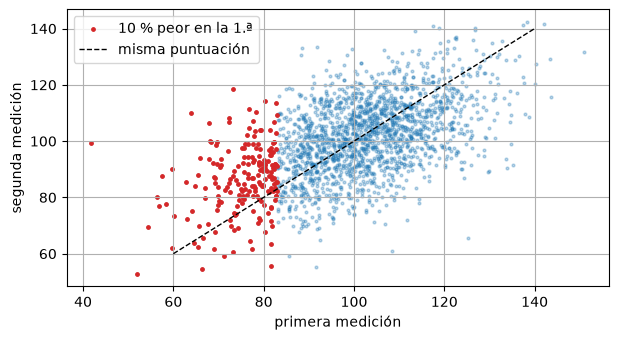

In [11]:
n = 2000
verdad = rng.normal(100, 10, size=n)              # el "valor real" de cada persona
medida1 = verdad + rng.normal(0, 10, size=n)      # primera medición, con ruido
medida2 = verdad + rng.normal(0, 10, size=n)      # segunda medición, ruido independiente

peores = medida1 < np.percentile(medida1, 10)     # elegimos el 10 % con peor primera medición
print(f"Promedio del 10 % 'peor' en la 1.ª medición: {medida1[peores].mean():.1f}")
print(f"Las mismas personas en la 2.ª medición:       {medida2[peores].mean():.1f}  (sin intervención alguna)")

plt.scatter(medida1, medida2, s=4, alpha=0.3)
plt.scatter(medida1[peores], medida2[peores], s=6, color="tab:red", label="10 % peor en la 1.ª")
plt.plot([60, 140], [60, 140], "k--", lw=1, label="misma puntuación")
plt.xlabel("primera medición"); plt.ylabel("segunda medición"); plt.legend(); plt.show()

## 6. La clase de referencia y la paradoja de Simpson (§5)

En agosto de 2021, titulares anunciaron que casi el 60 % de los hospitalizados por covid-19 en Israel estaban vacunados, y más de uno concluyó que la vacuna había dejado de funcionar. El capítulo explica por qué no: la edad estaba correlacionada a la vez con estar vacunado y con enfermar gravemente, y al *controlar por edad* la vacuna protegía en todos los grupos. Es la paradoja de Simpson: una asociación puede invertirse al cambiar la clase de referencia. Construimos aquí una población ficticia con esa estructura (los números son inventados para que el efecto se vea; no son los datos israelíes).

In [12]:
# Dos grupos de edad. Los mayores están casi todos vacunados y tienen mucho más riesgo de base.
grupos = {"menores de 50": dict(n=1_000_000, vacunados=0.55, riesgo_sin=0.0010, riesgo_con=0.0002),
          "mayores de 50": dict(n=  400_000, vacunados=0.95, riesgo_sin=0.0200, riesgo_con=0.0040)}

hosp_vac = hosp_novac = 0
for nombre, g in grupos.items():
    n_vac = g["n"] * g["vacunados"]; n_novac = g["n"] - n_vac
    h_vac = n_vac * g["riesgo_con"]; h_novac = n_novac * g["riesgo_sin"]
    hosp_vac += h_vac; hosp_novac += h_novac
    print(f"{nombre}: riesgo de hospitalización {g['riesgo_sin']*100:.2f} % sin vacuna, "
          f"{g['riesgo_con']*100:.2f} % con vacuna -> eficacia {100*(1-g['riesgo_con']/g['riesgo_sin']):.0f} %")

print(f"\nY sin embargo, de los {hosp_vac+hosp_novac:.0f} hospitalizados, "
      f"el {100*hosp_vac/(hosp_vac+hosp_novac):.0f} % está vacunado.")
print("Mirar solo la sala del hospital (la clase de referencia equivocada) sugiere lo contrario de lo que ocurre.")

menores de 50: riesgo de hospitalización 0.10 % sin vacuna, 0.02 % con vacuna -> eficacia 80 %
mayores de 50: riesgo de hospitalización 2.00 % sin vacuna, 0.40 % con vacuna -> eficacia 80 %

Y sin embargo, de los 2480 hospitalizados, el 66 % está vacunado.
Mirar solo la sala del hospital (la clase de referencia equivocada) sugiere lo contrario de lo que ocurre.


## 7. Contrastar hipótesis: la dama del té y el valor *p* (§8)

En el experimento con que Fisher presentó el contraste de hipótesis, una señora afirma distinguir si en una taza de té con leche se sirvió primero la leche o el té. Fisher le presenta ocho tazas, cuatro de cada tipo, en orden aleatorio, y ella debe elegir las cuatro en que se sirvió primero la leche. Si acierta las cuatro, ¿qué prueba eso?

El razonamiento es el siguiente. Suponemos la **hipótesis nula**: la señora no distingue nada y elige al azar. Bajo esa hipótesis calculamos la probabilidad de un resultado *al menos tan bueno* como el observado: ese es el **valor *p***. Si es muy pequeño, o bien ocurrió algo raro, o bien la hipótesis nula es falsa. Con 8 tazas hay 70 maneras de elegir 4, y solo una es la correcta: $p = 1/70 \approx 0{,}014$.

In [13]:
from math import comb
print(f"Maneras de elegir 4 tazas entre 8: {comb(8,4)}; acertar las 4 al azar: p = 1/{comb(8,4)} = {1/comb(8,4):.4f}")
print(f"Acertar 3 o más al azar: p = {(comb(4,3)*comb(4,1) + 1)/comb(8,4):.4f}")
print("Por eso Fisher pedía acierto perfecto: con 3 de 4 el resultado no sería raro bajo la hipótesis nula.")

# Simulación: una señora que elige al azar, muchas veces
ensayos = 100_000
aciertos = np.array([np.intersect1d(rng.choice(8, 4, replace=False), np.arange(4)).size for _ in range(ensayos)])
for k in range(5):
    print(f"  {k} aciertos: frecuencia {np.mean(aciertos == k):.4f}   (exacto: {comb(4,k)*comb(4,4-k)/comb(8,4):.4f})")

Maneras de elegir 4 tazas entre 8: 70; acertar las 4 al azar: p = 1/70 = 0.0143
Acertar 3 o más al azar: p = 0.2429
Por eso Fisher pedía acierto perfecto: con 3 de 4 el resultado no sería raro bajo la hipótesis nula.


  0 aciertos: frecuencia 0.0144   (exacto: 0.0143)
  1 aciertos: frecuencia 0.2302   (exacto: 0.2286)
  2 aciertos: frecuencia 0.5135   (exacto: 0.5143)
  3 aciertos: frecuencia 0.2283   (exacto: 0.2286)
  4 aciertos: frecuencia 0.0136   (exacto: 0.0143)


### Errores de tipo I y de tipo II, y la potencia

El contraste "por su propia naturaleza, no ofrece garantías": se puede rechazar una nula verdadera (**error de tipo I**, falso positivo) o no rechazar una nula falsa (**error de tipo II**, falso negativo). Bajar el umbral $\alpha$ para evitar el primero aumenta el riesgo del segundo. La **potencia** de un estudio es la probabilidad de detectar un efecto que realmente existe, y depende del tamaño del efecto y del tamaño de la muestra. Simulemos un ensayo que compara dos grupos.

In [14]:
def simular_ensayo(efecto, n_por_grupo, alpha=0.05, repeticiones=4000):
    # Devuelve la fracción de ensayos en que se rechaza la hipótesis nula "no hay diferencia".
    control = rng.normal(0, 1, size=(repeticiones, n_por_grupo))
    tratado = rng.normal(efecto, 1, size=(repeticiones, n_por_grupo))
    p = stats.ttest_ind(tratado, control, axis=1).pvalue
    return (p < alpha).mean()

print("Si el tratamiento NO hace nada (efecto = 0), la fracción de 'hallazgos' es el error de tipo I:")
for alpha in [0.05, 0.01, 0.001]:
    print(f"  alpha = {alpha}: se rechaza la nula en {simular_ensayo(0, 30, alpha):.3f} de los ensayos")

print("\nSi el tratamiento tiene un efecto moderado (0,4 desvíos), la fracción de hallazgos es la potencia:")
for n in [10, 30, 100, 300]:
    print(f"  n = {n:3d} por grupo: potencia {simular_ensayo(0.4, n):.3f}")

Si el tratamiento NO hace nada (efecto = 0), la fracción de 'hallazgos' es el error de tipo I:
  alpha = 0.05: se rechaza la nula en 0.052 de los ensayos
  alpha = 0.01: se rechaza la nula en 0.011 de los ensayos
  alpha = 0.001: se rechaza la nula en 0.001 de los ensayos

Si el tratamiento tiene un efecto moderado (0,4 desvíos), la fracción de hallazgos es la potencia:
  n =  10 por grupo: potencia 0.149
  n =  30 por grupo: potencia 0.329
  n = 100 por grupo: potencia 0.808
  n = 300 por grupo: potencia 0.999


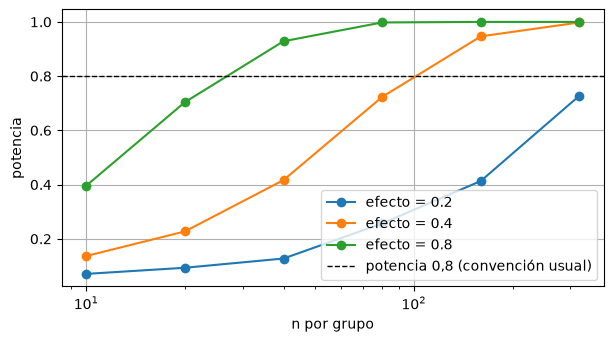

Un efecto pequeño con muestras chicas casi nunca se detecta; con muestras enormes, cualquier efecto
minúsculo se vuelve 'significativo'. Significativo no quiere decir importante.


In [15]:
# Potencia en función del tamaño de la muestra, para distintos tamaños de efecto
ns = [10, 20, 40, 80, 160, 320]
for efecto in [0.2, 0.4, 0.8]:
    plt.plot(ns, [simular_ensayo(efecto, n, repeticiones=1500) for n in ns], "o-", label=f"efecto = {efecto}")
plt.axhline(0.8, color="k", ls="--", lw=1, label="potencia 0,8 (convención usual)")
plt.xscale("log"); plt.xlabel("n por grupo"); plt.ylabel("potencia"); plt.legend(); plt.show()
print("Un efecto pequeño con muestras chicas casi nunca se detecta; con muestras enormes, cualquier efecto")
print("minúsculo se vuelve 'significativo'. Significativo no quiere decir importante.")

## 8. Comparaciones múltiples y el jardín de los senderos que se bifurcan (§9)

Si se examinan suficientes asociaciones, algunas cruzarán el umbral de significación por puro azar: con $\alpha = 0{,}05$, una de cada veinte asociaciones *inexistentes*. Es el distrito de Maryland de Salmon a escala industrial. Dos simulaciones: en la primera, medimos 20 variables que no tienen ninguna relación con el resultado y contamos cuántas resultan "significativas"; en la segunda, un investigador honesto pero impaciente mira los datos cada tanto y se detiene cuando encuentra $p < 0{,}05$ (la "detención opcional").

In [16]:
# 1. Veinte variables sin relación alguna con el resultado
n_personas, n_variables = 200, 20                        # <- probá cambiar esto
resultado = rng.normal(size=n_personas)
variables = rng.normal(size=(n_personas, n_variables))
pvals = np.array([stats.pearsonr(variables[:, j], resultado).pvalue for j in range(n_variables)])
print(f"Variables 'significativas' (p < 0,05) entre {n_variables} sin relación real: {(pvals < 0.05).sum()}")
print(f"Probabilidad de al menos un falso hallazgo con {n_variables} pruebas: 1 - 0,95^{n_variables} = {1-0.95**n_variables:.2f}")

# Repetimos el estudio entero muchas veces para ver la distribución
al_menos_uno = []
for _ in range(2000):
    r = rng.normal(size=n_personas); V = rng.normal(size=(n_personas, n_variables))
    ps = [stats.pearsonr(V[:, j], r).pvalue for j in range(n_variables)]
    al_menos_uno.append(min(ps) < 0.05)
print(f"En la simulación, {np.mean(al_menos_uno):.2f} de los estudios encuentran 'algo'.")

Variables 'significativas' (p < 0,05) entre 20 sin relación real: 0
Probabilidad de al menos un falso hallazgo con 20 pruebas: 1 - 0,95^20 = 0.64


En la simulación, 0.63 de los estudios encuentran 'algo'.


In [17]:
# 2. Detención opcional: se agregan participantes de a 10 y se mira p cada vez; se para al primer p < 0,05.
def estudio_impaciente(n_max=200, paso=10, alpha=0.05):
    control, tratado = [], []
    while len(control) < n_max:
        control.extend(rng.normal(0, 1, paso)); tratado.extend(rng.normal(0, 1, paso))   # efecto real = 0
        if len(control) >= 20 and stats.ttest_ind(tratado, control).pvalue < alpha:
            return True
    return False

falsos = np.mean([estudio_impaciente() for _ in range(2000)])
print(f"Con efecto real nulo, el investigador impaciente 'encuentra' un efecto en {falsos:.2f} de los estudios,")
print("cuando el umbral prometía 0,05. Mirar los datos y decidir cuándo parar es una decisión que el valor p no ve.")

Con efecto real nulo, el investigador impaciente 'encuentra' un efecto en 0.23 de los estudios,
cuando el umbral prometía 0,05. Mirar los datos y decidir cuándo parar es una decisión que el valor p no ve.


## 9. La crisis de replicación en miniatura (§9)

Juntemos las piezas. Supongamos que en un campo de investigación solo una fracción $\pi$ de las hipótesis que se ponen a prueba es verdadera, que los estudios tienen potencia $1-\beta$ y umbral $\alpha$, y que se publican los resultados significativos. ¿Qué fracción de los "hallazgos" publicados es verdadera? Es el mismo cálculo que el cribado médico de la sección 2, con las hipótesis en el lugar de los pacientes: la tasa de base de hipótesis verdaderas hace el mismo trabajo que la prevalencia.

In [18]:
def fraccion_verdadera(pi, potencia, alpha):
    verdaderos_positivos = pi * potencia
    falsos_positivos = (1 - pi) * alpha
    return verdaderos_positivos / (verdaderos_positivos + falsos_positivos)

print("Fracción de hallazgos publicados que son verdaderos:")
for pi in [0.5, 0.1, 0.01]:
    for potencia in [0.8, 0.2]:
        print(f"  {pi*100:4.0f} % de hipótesis verdaderas, potencia {potencia}: {fraccion_verdadera(pi, potencia, 0.05):.2f}")
print("\nCampos que ponen a prueba muchas hipótesis improbables con estudios de baja potencia producen")
print("literaturas en que la mayoría de los hallazgos son falsos, aunque nadie haga trampa.")

Fracción de hallazgos publicados que son verdaderos:
    50 % de hipótesis verdaderas, potencia 0.8: 0.94
    50 % de hipótesis verdaderas, potencia 0.2: 0.80
    10 % de hipótesis verdaderas, potencia 0.8: 0.64
    10 % de hipótesis verdaderas, potencia 0.2: 0.31
     1 % de hipótesis verdaderas, potencia 0.8: 0.14
     1 % de hipótesis verdaderas, potencia 0.2: 0.04

Campos que ponen a prueba muchas hipótesis improbables con estudios de baja potencia producen
literaturas en que la mayoría de los hallazgos son falsos, aunque nadie haga trampa.


## 10. Para seguir

Lo que este cuaderno muestra con simulaciones, el capítulo 8 lo discute como problema filosófico: qué es una probabilidad (§4), por qué la clase de referencia no la fija el cálculo (§5), qué aporta y qué no aporta el teorema de Bayes a la noción de confirmación (§6), y dónde queda el juicio cuando la estadística parece haberlo reemplazado (§8 y §10). Algunas cosas para hacer con lo aprendido:

1. En la sección 2, encontrá una combinación de prevalencia y exactitud para la cual un positivo signifique, por fin, "más probable enfermo que sano". ¿Qué tiene que ser más grande, la prueba o la tasa de base?
2. En la sección 3, probá con `theta_verdadero = 0.5` y una previa `Beta(2, 8)`: ¿cuántas tiradas hacen falta para que esa persona abandone su prejuicio? ¿Y con `Beta(1000, 1000)` y `theta_verdadero = 0.7`?
3. En la sección 8, bajá el umbral a `alpha = 0.005` (la propuesta de "redefinir la significación") y fijate qué pasa con las comparaciones múltiples y con la potencia de la sección 7 al mismo tiempo. Ahí está, en dos números, el argumento del riesgo inductivo del capítulo 9.
4. Escribí en una frase, sin fórmulas, qué le dirías a alguien que lee que "el 60 % de los hospitalizados está vacunado".

Para las lecturas, la *Nota de lecturas* del capítulo 8: Salmon para los fundamentos, *Recipes for Science* (caps. 9-11) para la práctica.